# Plots for Abby
- maps of mean, std, percent range in ET across obs products
- LAI-aridity bin percent range in ET across obs products

In [42]:
from pathlib import Path
from datetime import datetime

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

import etunc.config as cfg
from etunc.plotting import set_edge_ticks, MAP_KWARGS

In [43]:
def finish(fig, fout, to_save=True):
    tnow = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    fig.suptitle(f"for-abby.ipynb - {tnow}", x=0.5, ha="center", fontsize=10)
    if isinstance(fout, Path) and not fout.parent.exists():
        print(f"making dir: {fout.parent}")
        fout.parent.mkdir(parents=True, exist_ok=True)
    if to_save:
        plt.savefig(fout, dpi=300, bbox_inches="tight")
        print(fout)

## Load results

In [44]:
OBS_ROOT = Path("/glade/work/bbuchovecky/et_unc/proc/obs")
TAG = "qbin_pooled_all.lai15_ai15.1deg.199501-201412"

FIG_ROOT = cfg.FIG_ROOT
# FIG_ROOT = Path("/glade/u/home/bbuchovecky/projects/et_unc/fig/for/aswann")

ORD_MEMBER = [
    'CLASS-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'DOLCE-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'FLUXCOM-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'MOD16A2-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'MODIS-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'PMLv2.2a_MODIS-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'PMLv2.2c-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'SiTHv2-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'GLEAMv3.3a-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'GLEAMv4.3a-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
    'GLEAMv4.3b-GIMMS_LAI4g-GPCPv2.3-GEWEX.SRB',
]

RNG_CMAP = "magma_r"
RNG_VMIN = 0
RNG_VMAX = 200

inputs = xr.open_dataset(OBS_ROOT / "obs.inputs.1deg.199501-201412.nc")

qbin = {}
# for x in ("et", "et_clim", "land_area"):
for x in ("et_clim",):
    qbin[x] = xr.open_dataset(OBS_ROOT / "qbin" / f"obs.{x}.{TAG}.nc")

In [45]:
et = inputs.et.mean(dim="year")
n_valid = et.notnull().sum("member")

rng = et.max(dim="member") - et.min(dim="member")
avg = et.mean(dim="member")
rng_rel = rng / np.abs(avg) * 100
rng_rel = rng_rel.where((n_valid > 6) & (avg > 2))

In [46]:
qbin_et = qbin["et_clim"].et.sel(stats="mean")
n_valid = qbin_et.notnull().sum("member")

qbin_rng = qbin_et.max(dim="member") - qbin_et.min(dim="member")
qbin_avg = qbin_et.mean(dim="member")
qbin_rng_rel = qbin_rng / np.abs(qbin_avg) * 100
qbin_rng_rel = qbin_rng_rel.where((n_valid > 6) & (qbin_avg > 2))

## Panel maps of obs

/glade/u/home/bbuchovecky/projects/et_unc/fig/obs/clim/obs.et.1deg.panel_map.199501-201412.png


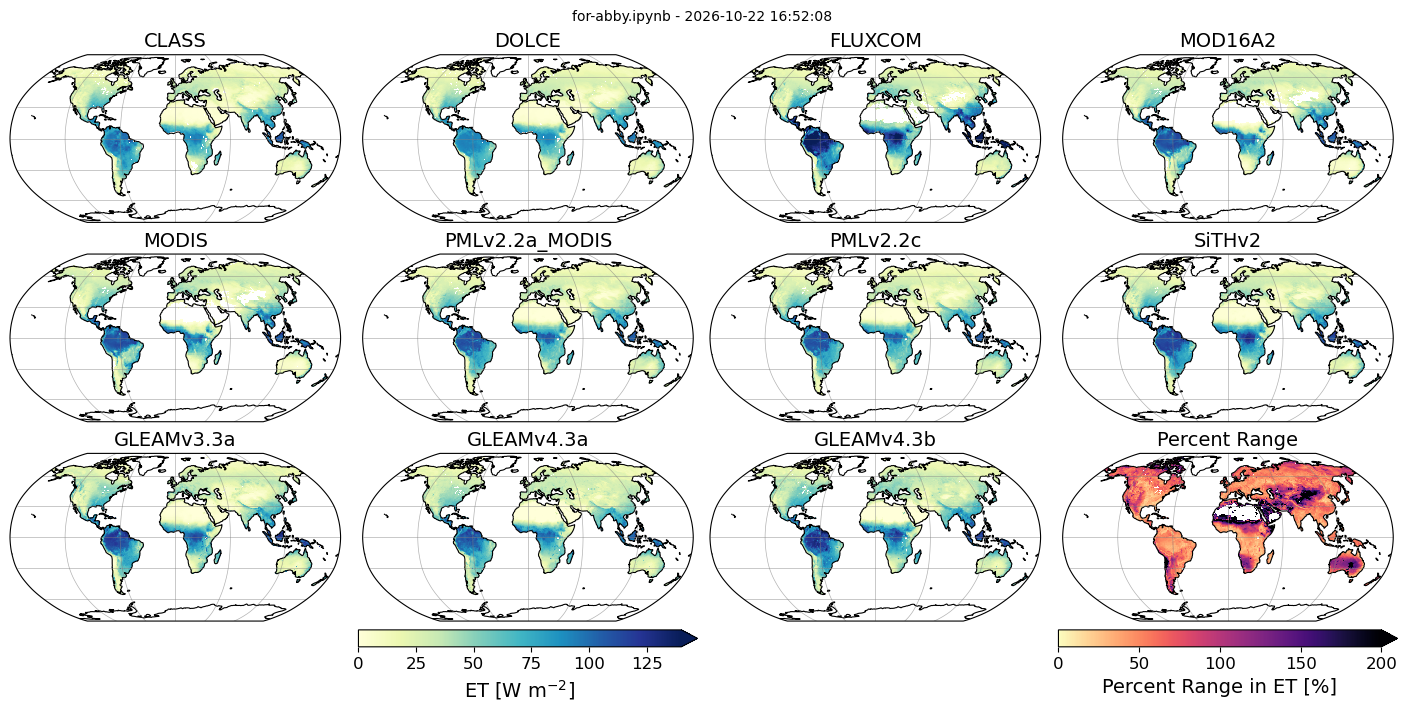

In [47]:
fig, axes = plt.subplots(3, 4, figsize=(14, 7), subplot_kw=dict(projection=ccrs.Robinson()), layout="constrained")
axs = axes.ravel()

for ax, m, etp in zip(axs, ORD_MEMBER, inputs.sel(member=ORD_MEMBER).et_product):
    mappable = inputs.et.sel(member=m).mean(dim="year").plot(
        ax=ax, 
        cmap=MAP_KWARGS["et"]["cmap"],
        vmin=0, vmax=140,
        add_labels=False,
        add_colorbar=False,
        transform=ccrs.PlateCarree(),
    )
    ax.set_global()
    ax.gridlines(color="gray", linewidth=0.5, alpha=0.6)
    ax.coastlines(lw=0.8, color="k")
    ax.set_title(etp.item(), fontsize=14)

cb = fig.colorbar(
    mappable,
    extend="max",
    # ax=axs[:-1],
    # fraction=0.025,
    # pad=0.01,
    ax=axs[-3],
    location="bottom",
)
cb.set_label("ET [W m$^{-2}$]", fontsize=14)
cb.ax.tick_params(labelsize=12)

# axs[-1].remove()

mappable = rng_rel.plot(
    ax=axs[-1],
    vmin=RNG_VMIN, vmax=RNG_VMAX,
    cmap=RNG_CMAP,
    add_labels=False,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
axs[-1].set_global()
axs[-1].gridlines(color="gray", linewidth=0.5, alpha=0.6)
axs[-1].coastlines(lw=0.8, color="k")
axs[-1].set_title("Percent Range", fontsize=14)
cb = fig.colorbar(
    mappable,
    extend="max",
    # ax=axs[:-1],
    # fraction=0.025,
    # pad=0.01,
    ax=axs[-1],
    location="bottom",
)
cb.set_label("Percent Range in ET [%]", fontsize=14)
cb.ax.tick_params(labelsize=12)

fout = FIG_ROOT / "obs" / "clim" / "obs.et.1deg.panel_map.199501-201412.png"
finish(fig, fout)

## Map of range across obs

/glade/u/home/bbuchovecky/projects/et_unc/fig/obs/clim/obs.et.1deg.rng_rel_map.199501-201412.png


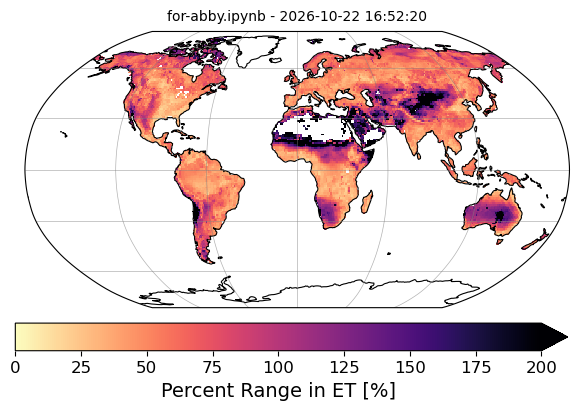

In [48]:
fig, ax = plt.subplots(figsize=(8, 4), subplot_kw=dict(projection=ccrs.Robinson()), layout="constrained")
mappable = rng_rel.plot(
    ax=ax,
    vmin=RNG_VMIN, vmax=RNG_VMAX,
    cmap=RNG_CMAP,
    add_labels=False,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ax.set_global()
ax.gridlines(color="gray", linewidth=0.5, alpha=0.6)
ax.coastlines(lw=0.8, color="k")
# ax.set_title("Percent Range in ET", fontsize=14)
cb = fig.colorbar(
    mappable,
    extend="max",
    fraction=0.1,
    ax=ax,
    location="bottom",
)
cb.set_label("Percent Range in ET [%]", fontsize=14)
cb.ax.tick_params(labelsize=12)

fout = FIG_ROOT / "obs" / "clim" / "obs.et.1deg.rng_rel_map.199501-201412.png"
finish(fig, fout)

## Bin range across obs

/glade/u/home/bbuchovecky/projects/et_unc/fig/obs/qbin/obs.et_clim.qbin_pooled_all.lai15_ai15.1deg.199501-201412.rng_rel.png


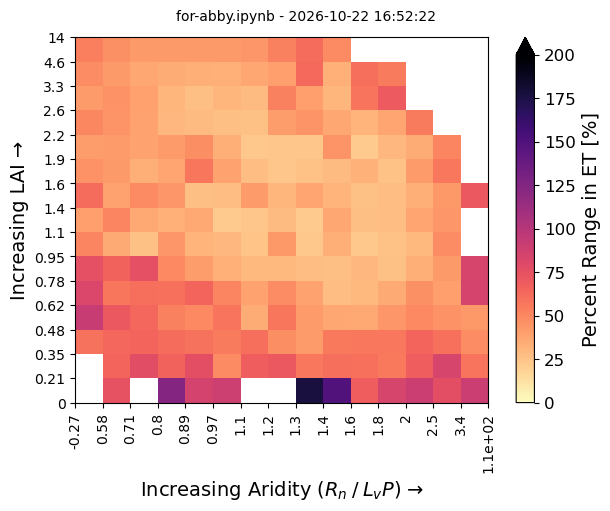

In [49]:
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
mappable = qbin_rng_rel.plot(
    ax=ax,
    cmap=RNG_CMAP,
    vmin=RNG_VMIN,
    vmax=RNG_VMAX,
    add_labels=False,
    add_colorbar=False,
)
set_edge_ticks(ax, qbin_rng_rel, "{:.2g}")
ax.tick_params(axis='both', labelsize=10)
ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →", fontsize=14)
ax.set_ylabel("Increasing LAI →", fontsize=14)
cb = fig.colorbar(
    mappable,
    ax=ax,
    extend="max",
)
cb.set_label("Percent Range in ET [%]", fontsize=14)
cb.ax.tick_params(labelsize=12)

fout = FIG_ROOT / "obs" / "qbin" / f"obs.et_clim.{TAG}.rng_rel.png"
finish(fig, fout)